# 🏈 Game Theory on the Gridiron
## Expected value, decision trees and Nash equilibrium with real NFL data

Football is full of decisions where the right answer depends on probabilities, and sometimes on what your **opponent** expects you to do. This notebook tackles two famous questions:

1. **After a touchdown, should you kick the extra point or go for 2?** (expected value and decision trees)
2. **Should you run or pass?** (game theory and **Nash equilibrium**)

### Learning goals
By the end you should be able to:
* compute an **expected value** and use a **decision tree** to compare strategies
* find the **break-even probability** where a decision flips
* read a **payoff matrix** and find each side's **best response**
* explain what a **Nash equilibrium** is, including **mixed strategies**
* solve a 2×2 game with the **indifference principle**, and test it against real NFL play-calling

### How to use this notebook
Run the cells **in order** (Runtime → Run all works too). Look for these boxes:

| Icon | Meaning |
|---|---|
| 💡 | **Key idea** |
| 🔍 | **Check your understanding**: answer in your head, then click to reveal |
| ✏️ | **Try it**: change a value and rerun the cell |

### Roadmap
| Part | Question | Tool |
|---|---|---|
| 0 | Setup | |
| 1 | Kick or go for 2? | expected value, decision trees |
| 2 | What makes something a "game"? | payoff matrices, best responses |
| 3 | Mixed strategies | Nash equilibrium, indifference principle |
| 4 | Run or pass in the real NFL? | Nash equilibrium with real data |
| 5 | Limitations and exercises | |

## Part 0 · Setup
Installs the data package ([nflverse](https://github.com/nflverse)) and loads the libraries. About 30 seconds the first time.

In [1]:
!pip -q install nflreadpy pyarrow

import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
SEASONS = list(range(2016, 2026))   # 2016–2025 regular seasons

### Team colors and logos
Helper functions for logos and team colors on the charts. You don't need to understand this code.

In [2]:
import io, urllib.request
from PIL import Image, ImageFilter
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from IPython.display import display, HTML

TEAM = nfl.load_teams().to_pandas().drop_duplicates("team_abbr").set_index("team_abbr")
COLOR  = TEAM.team_color.to_dict()     # primary color, e.g. COLOR["KC"] -> "#E31837"
COLOR2 = TEAM.team_color2.to_dict()    # secondary color
LOGO_URL = TEAM.team_logo_espn.to_dict()   # transparent PNG logos
LOGO_PX = 240                              # load logos at high resolution so they stay crisp
_logos = {}

def _white_outline(img, width=6):
    """Add a thin white outline around a transparent logo, like TV broadcast graphics."""
    pad = width * 2
    canvas = Image.new("RGBA", (img.width + 2 * pad, img.height + 2 * pad), (0, 0, 0, 0))
    canvas.paste(img, (pad, pad), img)
    grown = canvas.split()[3].filter(ImageFilter.MaxFilter(2 * width + 1))       # alpha mask, made fatter
    outline = Image.new("RGBA", canvas.size, (255, 255, 255, 255))
    outline.putalpha(grown.point(lambda a: 255 if a > 40 else 0))
    outline.alpha_composite(canvas)                                              # logo on top of the outline
    return outline

def get_logo(team):
    """Download a team logo once, cache it, and return it as a PIL image (or None)."""
    if team not in _logos:
        _logos[team] = None
        backup = (TEAM.at[team, "team_logo_squared"]
                  .replace("https://github.com/", "https://raw.githubusercontent.com/").replace("/raw/", "/"))
        for url in [TEAM.at[team, "team_logo_espn"], backup]:
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                img = Image.open(io.BytesIO(urllib.request.urlopen(req, timeout=10).read())).convert("RGBA")
                img.thumbnail((LOGO_PX, LOGO_PX), Image.LANCZOS)
                _logos[team] = _white_outline(img)
                break
            except Exception:
                pass
    return _logos[team]

def add_logo(ax, team, x, y, zoom=0.28):
    """Place a team logo on a matplotlib chart at data coordinates (x, y)."""
    img = get_logo(team)
    if img is None:   # fallback: team-colored dot with the abbreviation
        ax.scatter(x, y, s=420, color=COLOR.get(team, "gray"), edgecolor="white", zorder=3)
        ax.annotate(team, (x, y), ha="center", va="center", color="white", fontsize=7, weight="bold", zorder=4)
    else:
        size_fix = 120 / LOGO_PX   # keeps logos the same size on screen, just sharper
        ax.add_artist(AnnotationBbox(OffsetImage(img, zoom=zoom * size_fix), (x, y), frameon=False, zorder=3))

def logo_html(team, width=30):
    return (f'<img src="{LOGO_URL.get(team, "")}" width="{width}" '
            f'style="vertical-align:middle;filter:drop-shadow(0 0 1px white) drop-shadow(0 1px 2px rgba(0,0,0,.35))">')

print("Loaded colors/logos for", len(TEAM), "team codes")

Loaded colors/logos for 36 team codes


### Load play-by-play data
Every play from 2016 to 2025, plus **participation data**, which records how many defenders lined up "in the box" (close to the line of scrimmage) on each snap. This takes a minute or two.

In [3]:
cols = ["game_id", "play_id", "season", "season_type", "week", "posteam", "defteam", "down", "ydstogo",
        "yardline_100", "score_differential", "game_seconds_remaining", "wp", "pass", "rush", "epa", "success",
        "qb_kneel", "qb_spike", "two_point_conv_result", "extra_point_result"]
pbp = nfl.load_pbp(seasons=SEASONS).select(cols).to_pandas()
pbp = pbp[pbp.season_type == "REG"].copy()

box = (nfl.load_participation(seasons=SEASONS).to_pandas()
          [["nflverse_game_id", "play_id", "defenders_in_box"]]
          .rename(columns={"nflverse_game_id": "game_id"}))
print(f"{len(pbp):,} plays loaded, {box.defenders_in_box.notna().sum():,} with a defenders-in-the-box count")

462,773 plays loaded, 390,340 with a defenders-in-the-box count


## Part 1 · Kick the extra point or go for 2?

After a touchdown a team chooses:
* **Kick** the extra point from the 15-yard line, worth **1 point**, or
* **Go for 2**: run one play from the 2-yard line, worth **2 points** if it works.

This isn't really a "game" against the other team yet. It's a **decision under uncertainty**, and the tool is **expected value**.

### Step 1: How often does each one work?

Extra point:  11,546 made out of 12,228 tries  →  94.4%
Go for 2:     586 made out of 1,228 tries  →  47.7%


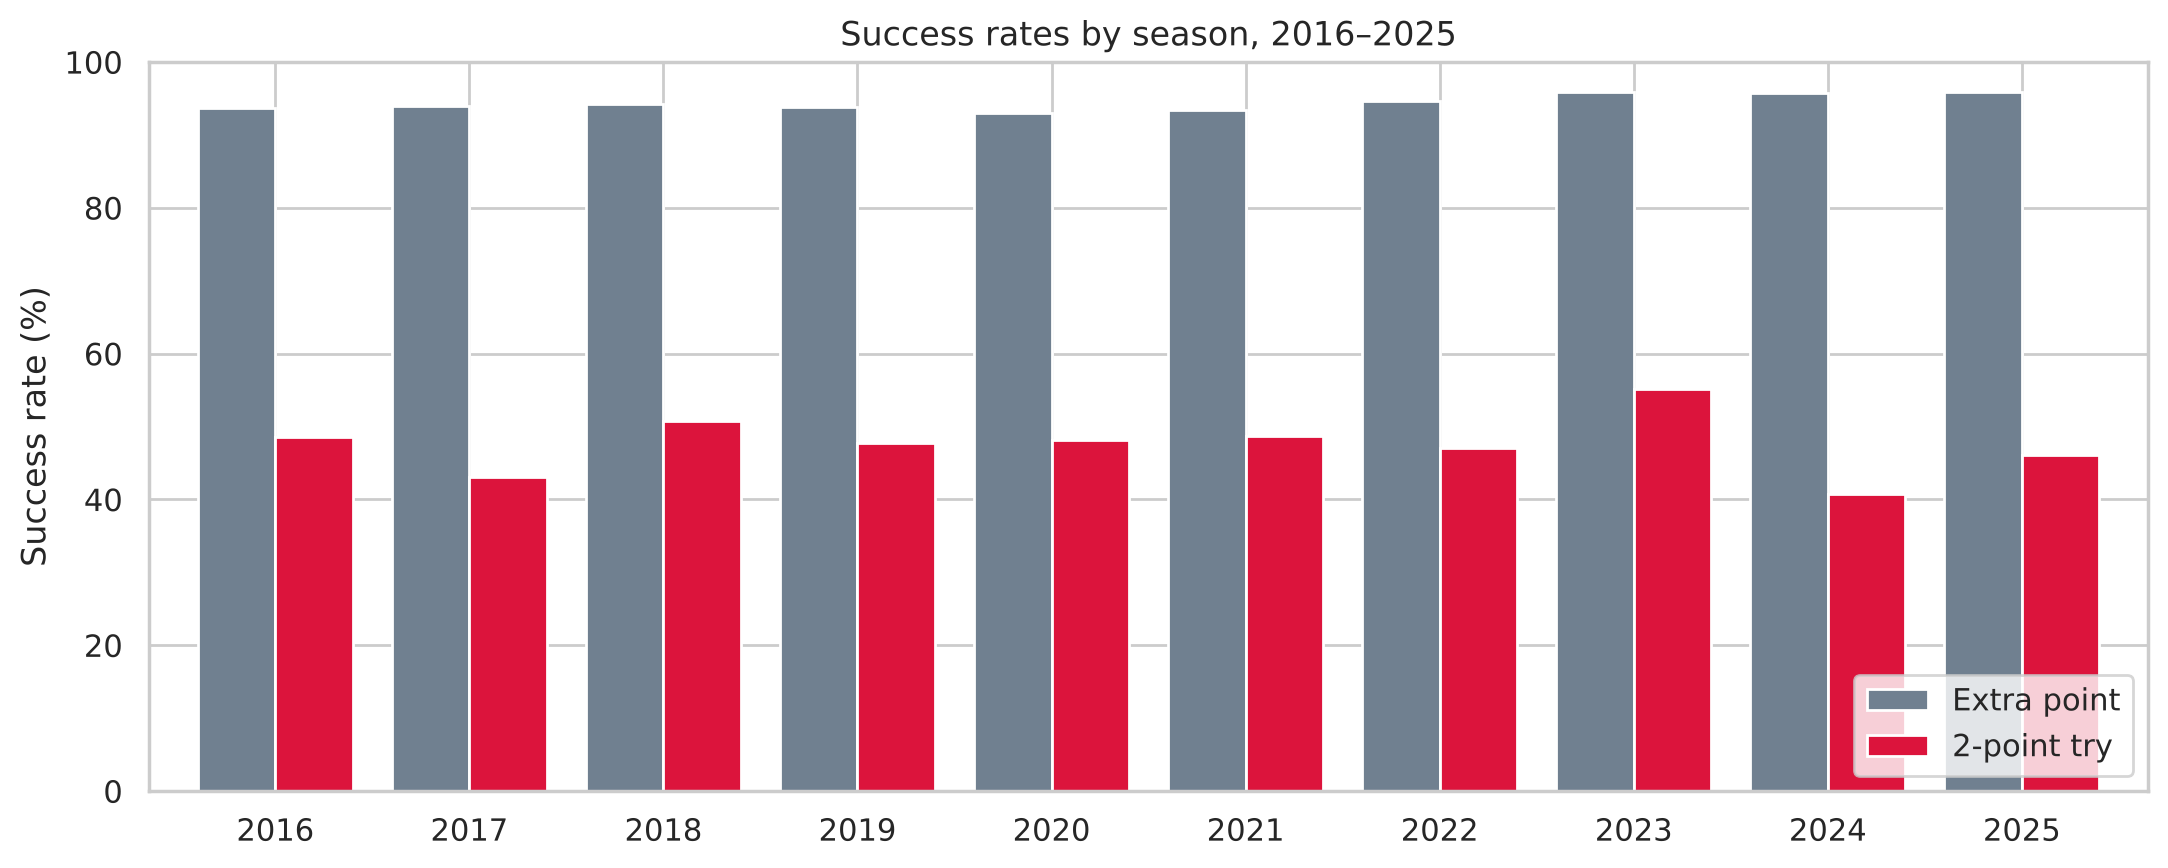

In [4]:
kicks = pbp[pbp.extra_point_result.notna()]
twos  = pbp[pbp.two_point_conv_result.notna()]
x = (kicks.extra_point_result == "good").mean()     # extra point success rate
p = (twos.two_point_conv_result == "success").mean()  # 2-point success rate

print(f"Extra point:  {(kicks.extra_point_result == 'good').sum():,} made out of {len(kicks):,} tries  →  {x:.1%}")
print(f"Go for 2:     {(twos.two_point_conv_result == 'success').sum():,} made out of {len(twos):,} tries  →  {p:.1%}")

by_season = pd.DataFrame({
    "Extra point": kicks.groupby("season").extra_point_result.apply(lambda s: (s == "good").mean()),
    "2-point try": twos.groupby("season").two_point_conv_result.apply(lambda s: (s == "success").mean()),
})
ax = (by_season * 100).plot(kind="bar", figsize=(11, 4.5), color=["slategray", "crimson"], width=.8)
ax.set(ylabel="Success rate (%)", xlabel="", ylim=(0, 100), title="Success rates by season, 2016–2025")
ax.legend(loc="lower right"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Step 2: Expected value
The **expected value** of a choice is *points if it works × chance it works*, the average number of points you'd get if you made that choice over and over.

$$EV(\text{kick}) = 1 \times x \qquad\qquad EV(\text{go for 2}) = 2 \times p$$

In [5]:
ev_kick, ev_two = 1 * x, 2 * p
print(f"EV(kick)     = 1 × {x:.3f} = {ev_kick:.3f} points")
print(f"EV(go for 2) = 2 × {p:.3f} = {ev_two:.3f} points")
print(f"Difference   = {ev_two - ev_kick:+.3f} points per try")

EV(kick)     = 1 × 0.944 = 0.944 points
EV(go for 2) = 2 × 0.477 = 0.954 points
Difference   = +0.010 points per try


💡 **Key idea:** on average the two choices are worth almost exactly the same, about 0.95 points. So the average doesn't decide it. **The score and time do.** When there's no time for anything else, what matters isn't average points but the **chance of winning**.

### Step 3: A decision tree for the famous "down 14" situation
You trail by **14** late in the game. You score a touchdown, so you're down **8** before the try. Assume you'll get the ball back and score **one more touchdown**, and the other team won't score again. Overtime is a coin flip (50%).

**Plan A: kick now (the traditional choice)**
```
Kick now ──── made (x) ──── down 7 → next TD + kick: made (x) → tie → OT (50%)
         │                                         └ missed → lose
         └─── missed (1−x) ─ down 8 → next TD + go for 2: made (p) → tie → OT (50%)
```
**Plan B: go for 2 now (the analytics choice)**
```
Go for 2 now ── made (p) ──── down 6 → next TD + kick: made (x) → WIN
           │                                       └ missed → tie → OT (50%)
           └─── failed (1−p) ─ down 8 → next TD + go for 2: made (p) → tie → OT (50%)
```
To get each plan's chance of winning, multiply the probabilities along each path and add up the paths:

$$P(\text{win} \mid A) = x \cdot x \cdot 0.5 \;+\; (1-x) \cdot p \cdot 0.5$$

$$P(\text{win} \mid B) = p \cdot \big(x \cdot 1 + (1-x) \cdot 0.5\big) \;+\; (1-p) \cdot p \cdot 0.5$$

In [6]:
def win_kick_first(x, p):
    return x * x * 0.5 + (1 - x) * p * 0.5

def win_two_first(x, p):
    return p * (x * 1 + (1 - x) * 0.5) + (1 - p) * p * 0.5

print(f"Using NFL success rates: extra point x = {x:.3f}, 2-point p = {p:.3f}\n")
print(f"Plan A (kick first):     chance of winning = {win_kick_first(x, p):.1%}")
print(f"Plan B (go for 2 first): chance of winning = {win_two_first(x, p):.1%}")

Using NFL success rates: extra point x = 0.944, 2-point p = 0.477

Plan A (kick first):     chance of winning = 45.9%
Plan B (go for 2 first): chance of winning = 58.9%


> 🔍 **Check your understanding:** Why does going for 2 first help, even though both choices are worth about the same on average?

<details><summary><b>Click to reveal the answer</b></summary>

**Information.** If the 2-point try works, you know you only need a touchdown and a kick to win outright. If it fails, you still have a second chance to go for 2 and tie. Kicking first leaves you needing everything to go right just to reach overtime. Going for 2 early gives you two shots at the 2 points you need, instead of one.

</details>

### Step 4: ✏️ The break-even point
How good does your 2-point offense need to be for Plan B to be the right call? Let's try every success rate from 0% to 100%.

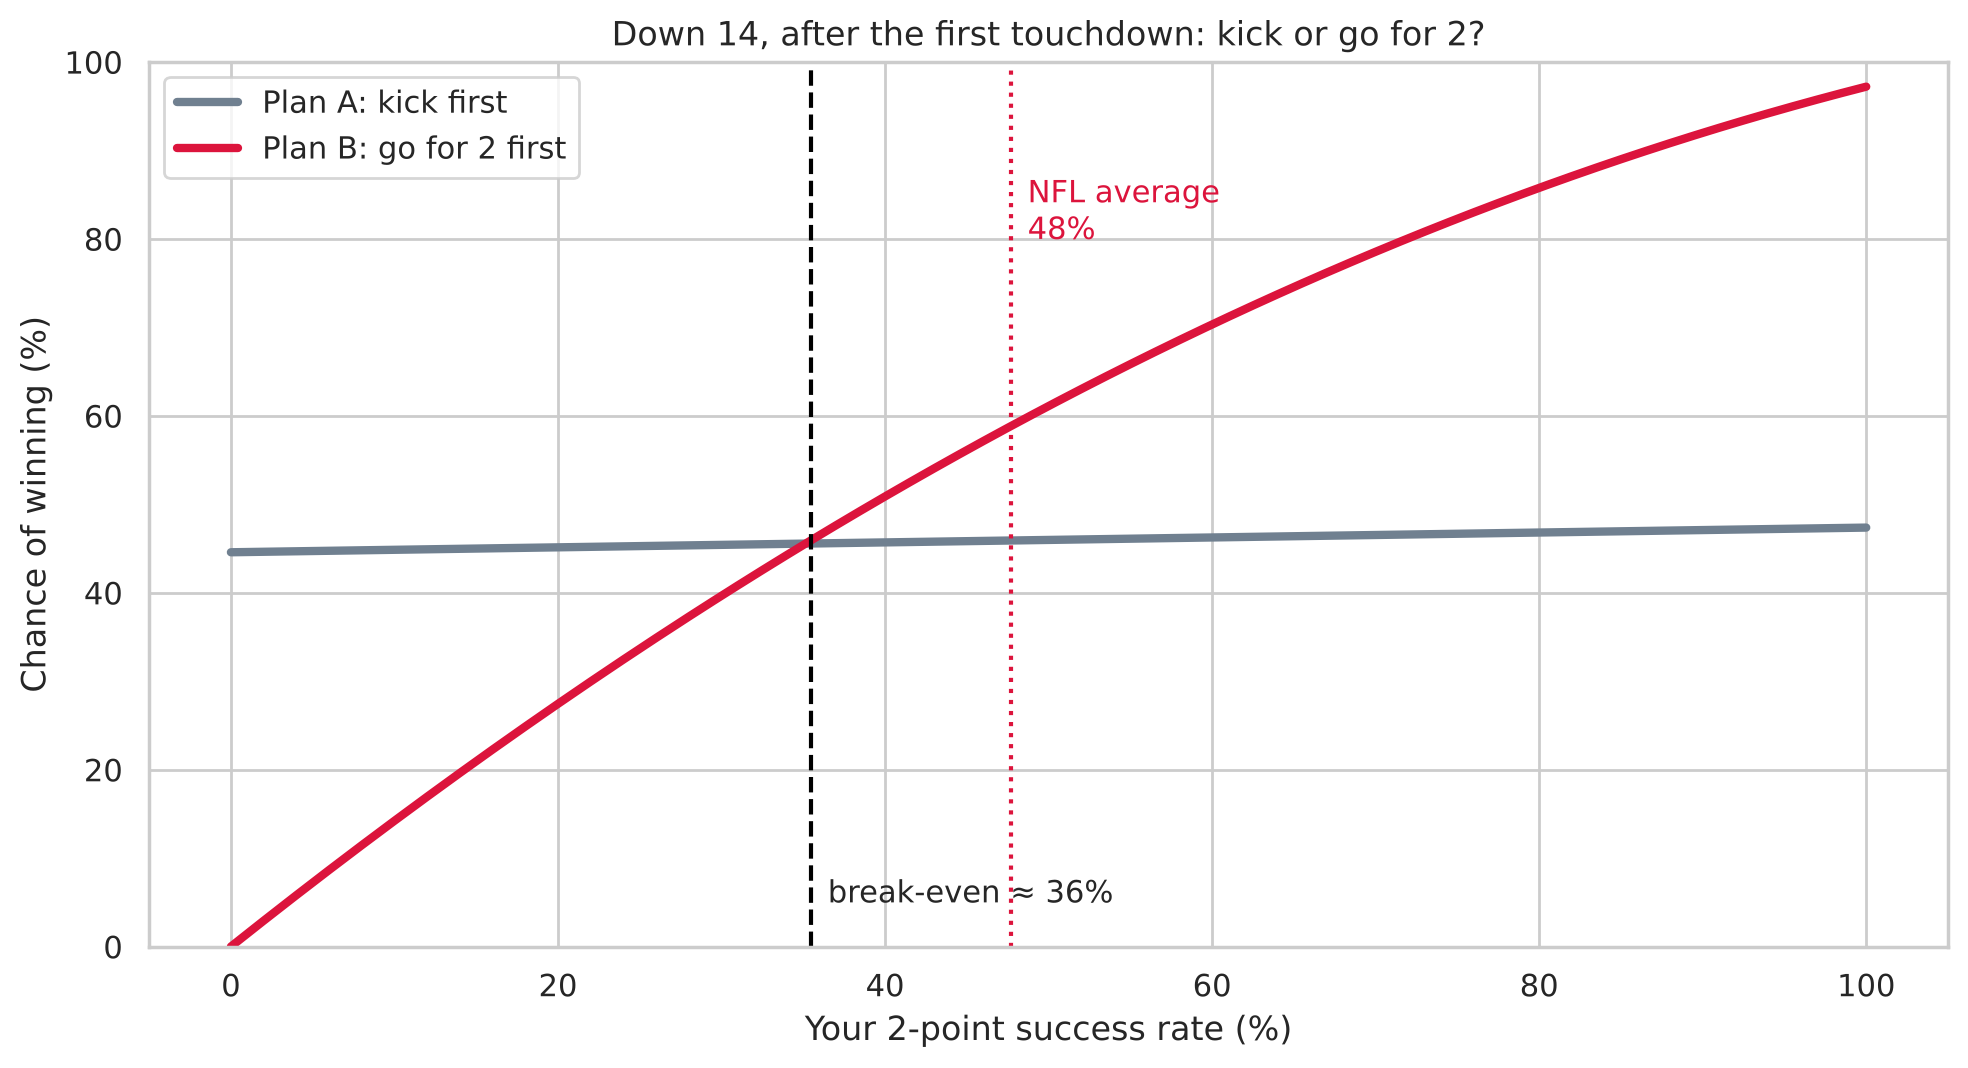

Going for 2 first is better whenever your 2-point success rate is above about 36%.


In [7]:
ps = np.linspace(0, 1, 201)
A, B = win_kick_first(x, ps), win_two_first(x, ps)
breakeven = ps[np.argmax(B >= A)]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(ps * 100, A * 100, lw=3, color="slategray", label="Plan A: kick first")
ax.plot(ps * 100, B * 100, lw=3, color="crimson", label="Plan B: go for 2 first")
ax.axvline(breakeven * 100, ls="--", color="black")
ax.axvline(p * 100, ls=":", color="crimson")
ax.text(breakeven * 100 + 1, 5, f"break-even ≈ {breakeven:.0%}", fontsize=11)
ax.text(p * 100 + 1, 80, f"NFL average\n{p:.0%}", color="crimson", fontsize=11)
ax.set(xlabel="Your 2-point success rate (%)", ylabel="Chance of winning (%)", ylim=(0, 100),
       title="Down 14, after the first touchdown: kick or go for 2?")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

print(f"Going for 2 first is better whenever your 2-point success rate is above about {breakeven:.0%}.")

> 🔍 **Check your understanding:** NFL teams make about 48% of 2-point tries. Based on the chart, how confident should a coach be in going for 2 first?

<details><summary><b>Click to reveal the answer</b></summary>

Very confident. The break-even point is well below the NFL average, so even a team with a below-average 2-point offense should go for 2 first in this spot. Yet many coaches still kick, because a failed 2-point try *feels* worse (and gets criticized more) even when it's the better bet.

</details>

## Part 2 · What makes something a "game"?

The kick-or-go decision only depended on probabilities. **Run or pass** is different: whether a run works depends on what the **defense** is expecting, and the defense's best setup depends on what it thinks the **offense** will do. When each side's best choice depends on the other's, it's a **game**.

### The vocabulary
| Term | Meaning | In our example |
|---|---|---|
| **Players** | the decision makers | the offense and the defense |
| **Strategies** | the choices each player can make | offense: run or pass; defense: stop the run or stop the pass |
| **Payoff** | what each player gets for each combination | yards gained (good for the offense, bad for the defense) |
| **Zero-sum** | one side's gain is exactly the other's loss | every yard the offense gains, the defense gives up |

### A toy example with round numbers
Suppose these are the average yards gained for each combination:

| | Defense expects **run** | Defense expects **pass** |
|---|---|---|
| **Offense runs** | 2 | 6 |
| **Offense passes** | 9 | 4 |

The offense wants **big** numbers, the defense wants **small** ones.

In [8]:
def show_game(matrix, title, row_player="Offense", col_player="Defense", fmt="{:.1f}"):
    """Show a 2×2 zero-sum game. ★ = offense's best response to that defense; ◆ = defense's best response to that play."""
    m = matrix.values
    off_best = m.argmax(axis=0)        # for each defense column, the offense's best row
    def_best = m.argmin(axis=1)        # for each offense row, the defense's best column
    lo, hi = m.min(), m.max()
    head = "".join(f"<th style='padding:10px 18px'>{col_player}: {c}</th>" for c in matrix.columns)
    rows = ""
    for i, r in enumerate(matrix.index):
        tds = ""
        for j in range(m.shape[1]):
            t = (m[i, j] - lo) / (hi - lo + 1e-9)
            bg = f"rgba({int(220 - 120 * t)},{int(120 + 100 * t)},{int(120)},0.35)"
            marks = ("★" if off_best[j] == i else "") + ("◆" if def_best[i] == j else "")
            nash = off_best[j] == i and def_best[i] == j
            border = "3px solid gold" if nash else "1px solid #ccc"
            tds += (f"<td style='padding:14px 22px;background:{bg};border:{border};font-size:18px'>"
                    f"<b>{fmt.format(m[i, j])}</b> <span style='font-size:14px'>{marks}</span></td>")
        rows += f"<tr><th style='padding:10px 18px;text-align:right'>{row_player}: {r}</th>{tds}</tr>"
    display(HTML(f"""<div style="font-family:sans-serif"><h4>{title}</h4>
      <table style="border-collapse:collapse;text-align:center"><tr><th></th>{head}</tr>{rows}</table>
      <div style="font-size:12px;color:#555;margin-top:6px">★ offense's best response to that defense &nbsp;·&nbsp;
      ◆ defense's best response to that play &nbsp;·&nbsp; gold border = both (a pure Nash equilibrium)</div></div>"""))

toy = pd.DataFrame([[2, 6], [9, 4]], index=["Run", "Pass"], columns=["expects run", "expects pass"])
show_game(toy, "Toy game: average yards gained")

,Defense: expects run,Defense: expects pass
Offense: Run,2.0 ◆,6.0 ★
Offense: Pass,9.0 ★,4.0 ◆


### Best responses
A **best response** is the best thing to do *if you knew* what the other side was doing.

* If the defense expects the run, the offense should **pass** (9 > 2). ★
* If the defense expects the pass, the offense should **run** (6 > 4). ★
* If the offense runs, the defense should expect the **run** (2 < 6). ◆
* If the offense passes, the defense should expect the **pass** (4 < 9). ◆

A **Nash equilibrium** is a pair of strategies where **each side is already playing a best response to the other**, so nobody wants to change their choice. In the table, that would be a cell with both ★ and ◆ (a gold border).

There isn't one! Whatever the two sides pick, someone wants to switch. It's like rock-paper-scissors: if you always do the same thing, the other side exploits you.

> 🔍 **Check your understanding:** Imagine the offense announced it would pass on every play. What would the defense do, and how many yards would the offense average?

<details><summary><b>Click to reveal the answer</b></summary>

The defense would always expect the pass, and the offense would average only 4 yards. Being predictable lets the other side play its best response every time.

</details>

## Part 3 · Mixed strategies: being unpredictable on purpose

The fix is to **randomize**: pass some fraction $q$ of the time and run the rest. This is a **mixed strategy**. John Nash proved that every game like this has an equilibrium once mixed strategies are allowed.

### The indifference principle
💡 **Key idea:** at the equilibrium, the offense mixes in exactly the proportion that makes the defense **indifferent**, so the defense gains nothing by guessing one way or the other. (If the defense weren't indifferent, it would lean toward one choice, and the offense could exploit that.)

If the offense passes with probability $q$, the defense's two options give:

$$\text{expects run: } \; 2(1-q) + 9q \qquad\qquad \text{expects pass: } \; 6(1-q) + 4q$$

Set them equal and solve: $2 + 7q = 6 - 2q$, so $q = 4/9 \approx 44\%$.

The same logic gives the defense's mix $r$ (the chance it expects the run): it makes the **offense** indifferent between running and passing.

In [9]:
def solve_2x2(matrix):
    """Mixed Nash equilibrium of a 2×2 zero-sum game (rows: Run, Pass; columns: defense options).
    Returns the offense's pass probability, the defense's first-column probability, and the game's value."""
    (a, b), (c, d) = matrix.values          # a = run vs col1, b = run vs col2, c = pass vs col1, d = pass vs col2
    denom = (a - b) - (c - d)
    q = (a - b) / denom                      # offense's pass probability (makes the defense indifferent)
    r = (d - b) / ((a - b) + (d - c))        # defense's chance of choosing column 1 (makes the offense indifferent)
    value = (1 - q) * (r * a + (1 - r) * b) + q * (r * c + (1 - r) * d)
    return q, r, value

q_toy, r_toy, v_toy = solve_2x2(toy)
print(f"Offense should pass {q_toy:.0%} of the time (run {1 - q_toy:.0%})")
print(f"Defense should expect the run {r_toy:.0%} of the time (expect the pass {1 - r_toy:.0%})")
print(f"Value of the game: the offense averages {v_toy:.2f} yards per play")

Offense should pass 44% of the time (run 56%)
Defense should expect the run 22% of the time (expect the pass 78%)
Value of the game: the offense averages 5.11 yards per play


### Picture it: the offense's guarantee
For every pass rate $q$, the defense will pick whichever setup hurts the offense more. So the offense can only count on the **lower** of the two lines below. The best guarantee is at the peak of that lower edge, which is exactly the Nash mix.

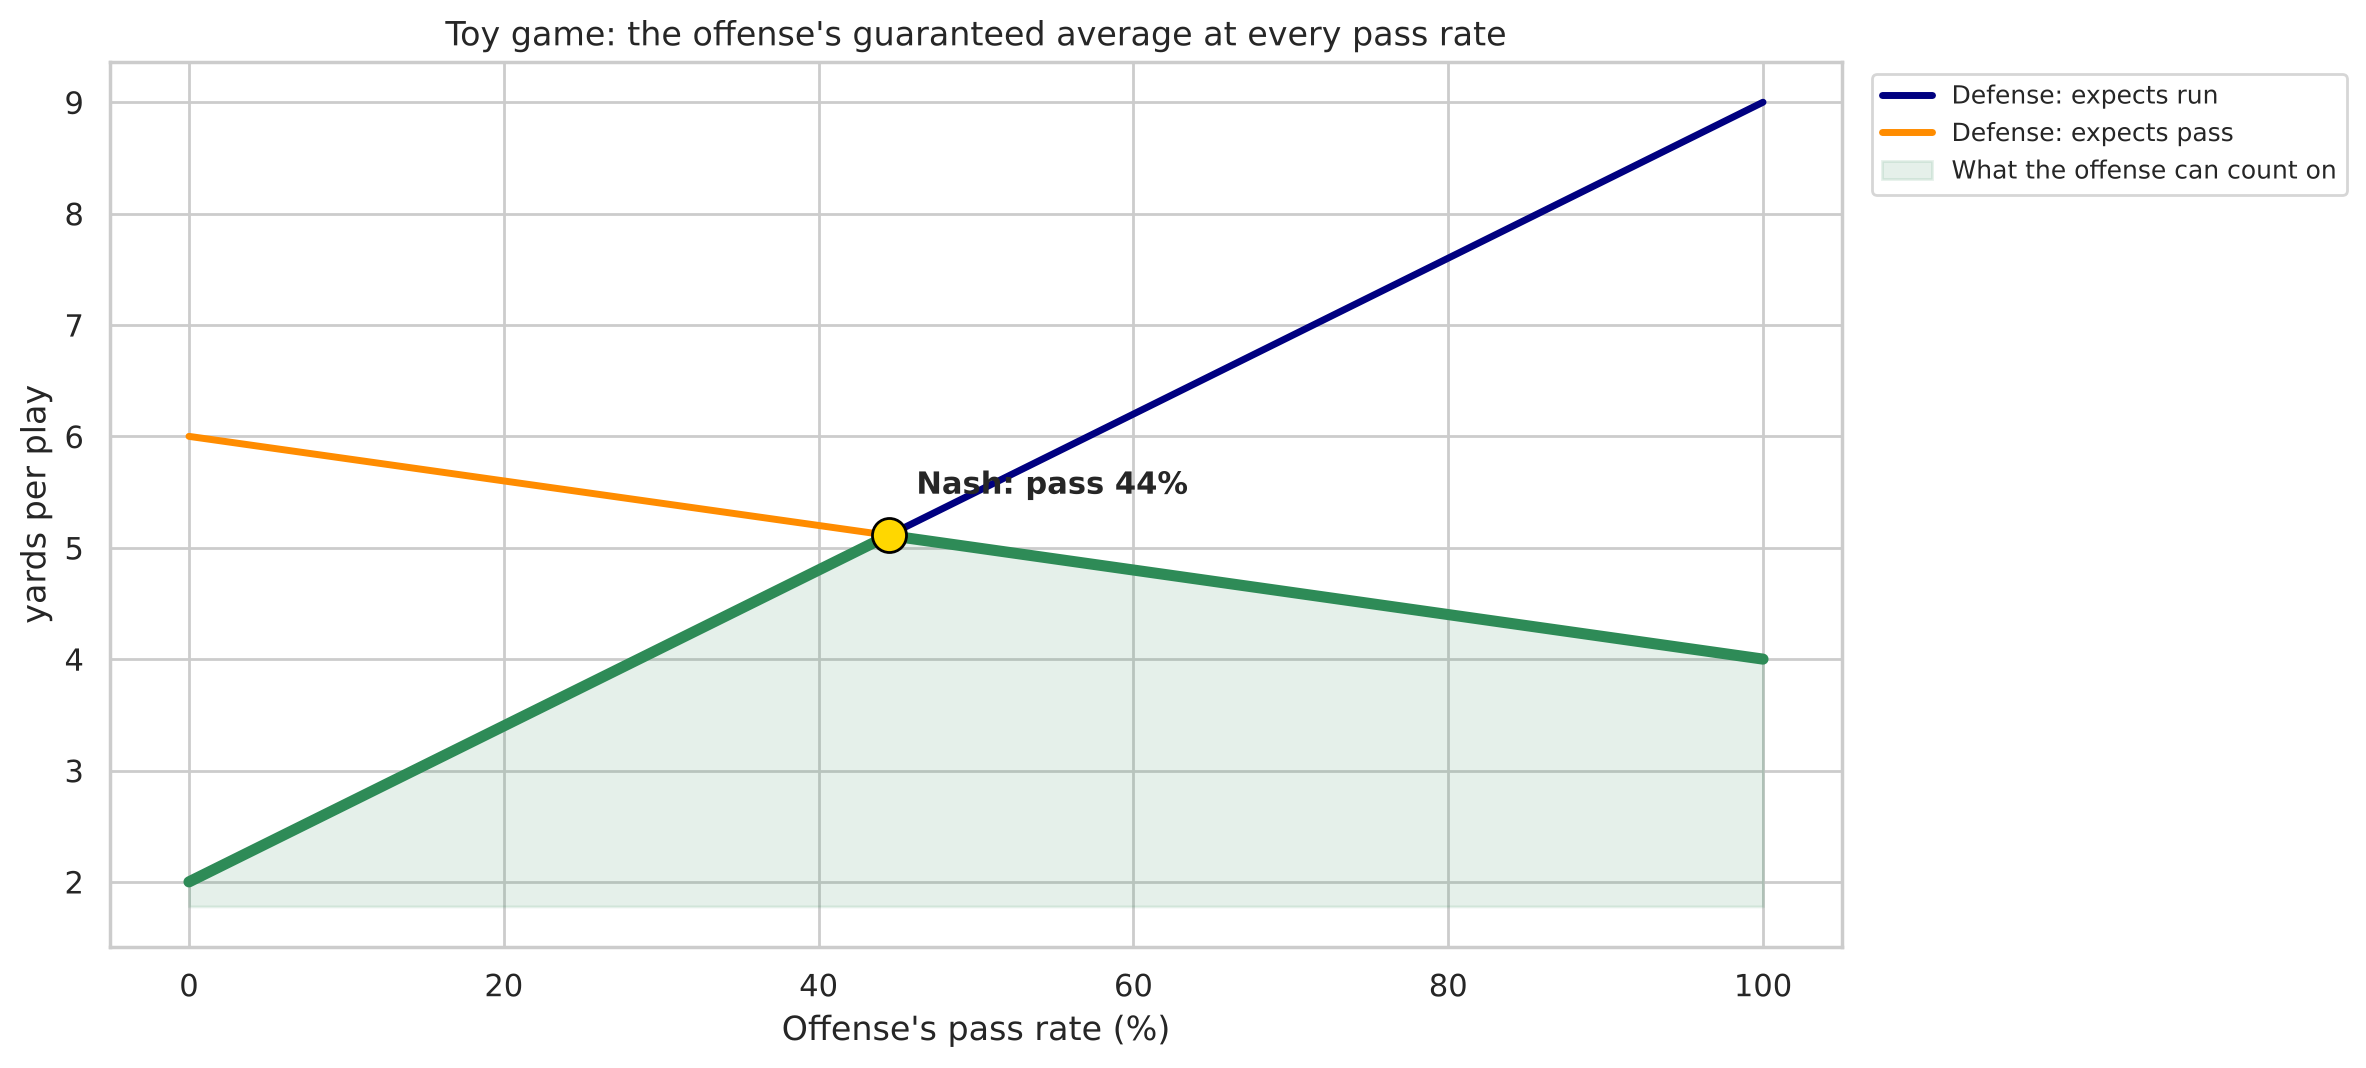

In [10]:
def minimax_plot(matrix, title, actual_q=None, units="yards per play"):
    qs = np.linspace(0, 1, 201)
    (a, b), (c, d) = matrix.values
    vs_col1 = (1 - qs) * a + qs * c
    vs_col2 = (1 - qs) * b + qs * d
    floor = np.minimum(vs_col1, vs_col2)
    q_star, _, value = solve_2x2(matrix)

    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.plot(qs * 100, vs_col1, color="navy", lw=2.5, label=f"Defense: {matrix.columns[0]}")
    ax.plot(qs * 100, vs_col2, color="darkorange", lw=2.5, label=f"Defense: {matrix.columns[1]}")
    ax.fill_between(qs * 100, floor, floor.min() - abs(floor.min()) * 0.1 - 0.02, color="seagreen", alpha=.12,
                    label="What the offense can count on")
    ax.plot(qs * 100, floor, color="seagreen", lw=4)
    ax.scatter(q_star * 100, value, s=150, color="gold", edgecolor="black", zorder=5)
    ax.annotate(f"Nash: pass {q_star:.0%}", (q_star * 100, value), xytext=(10, 15), textcoords="offset points",
                fontsize=11, weight="bold")
    if actual_q is not None:
        ax.axvline(actual_q * 100, color="crimson", ls="--", lw=2, label=f"What NFL teams actually do ({actual_q:.0%} pass)")
    ax.set(xlabel="Offense's pass rate (%)", ylabel=units, title=title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9); plt.tight_layout(); plt.show()

minimax_plot(toy, "Toy game: the offense's guaranteed average at every pass rate")

> 🔍 **Check your understanding:** In the toy game, the offense averages 5.1 yards at the Nash mix. Why can't it do better against a smart defense?

<details><summary><b>Click to reveal the answer</b></summary>

Any other mix leans one way, and the defense will set up for that lean. The Nash mix is the only pass rate where the defense's choice doesn't matter, so it's the best the offense can *guarantee*. (Against a defense that guesses badly, the offense could do better, but it can't count on that.)

</details>

## Part 4 · Run or pass in the real NFL

Now let's use real plays. We need real versions of each piece:

* **Payoff: EPA (expected points added).** How much a play changed the number of points the offense can expect to score on that drive. It's better than yards: a 3-yard run on 3rd & 2 is great, while a 3-yard run on 3rd & 10 is bad.
* **The defense's strategy: the box count.** Defenses that expect a run crowd more players near the line. We'll call **7 or more** defenders in the box a **"heavy box" (set up for the run)** and **6 or fewer** a **"light box" (set up for the pass)**.

We keep normal situations: real runs and passes (no kneel-downs or spikes) while the game is still competitive (each team between 10% and 90% to win).

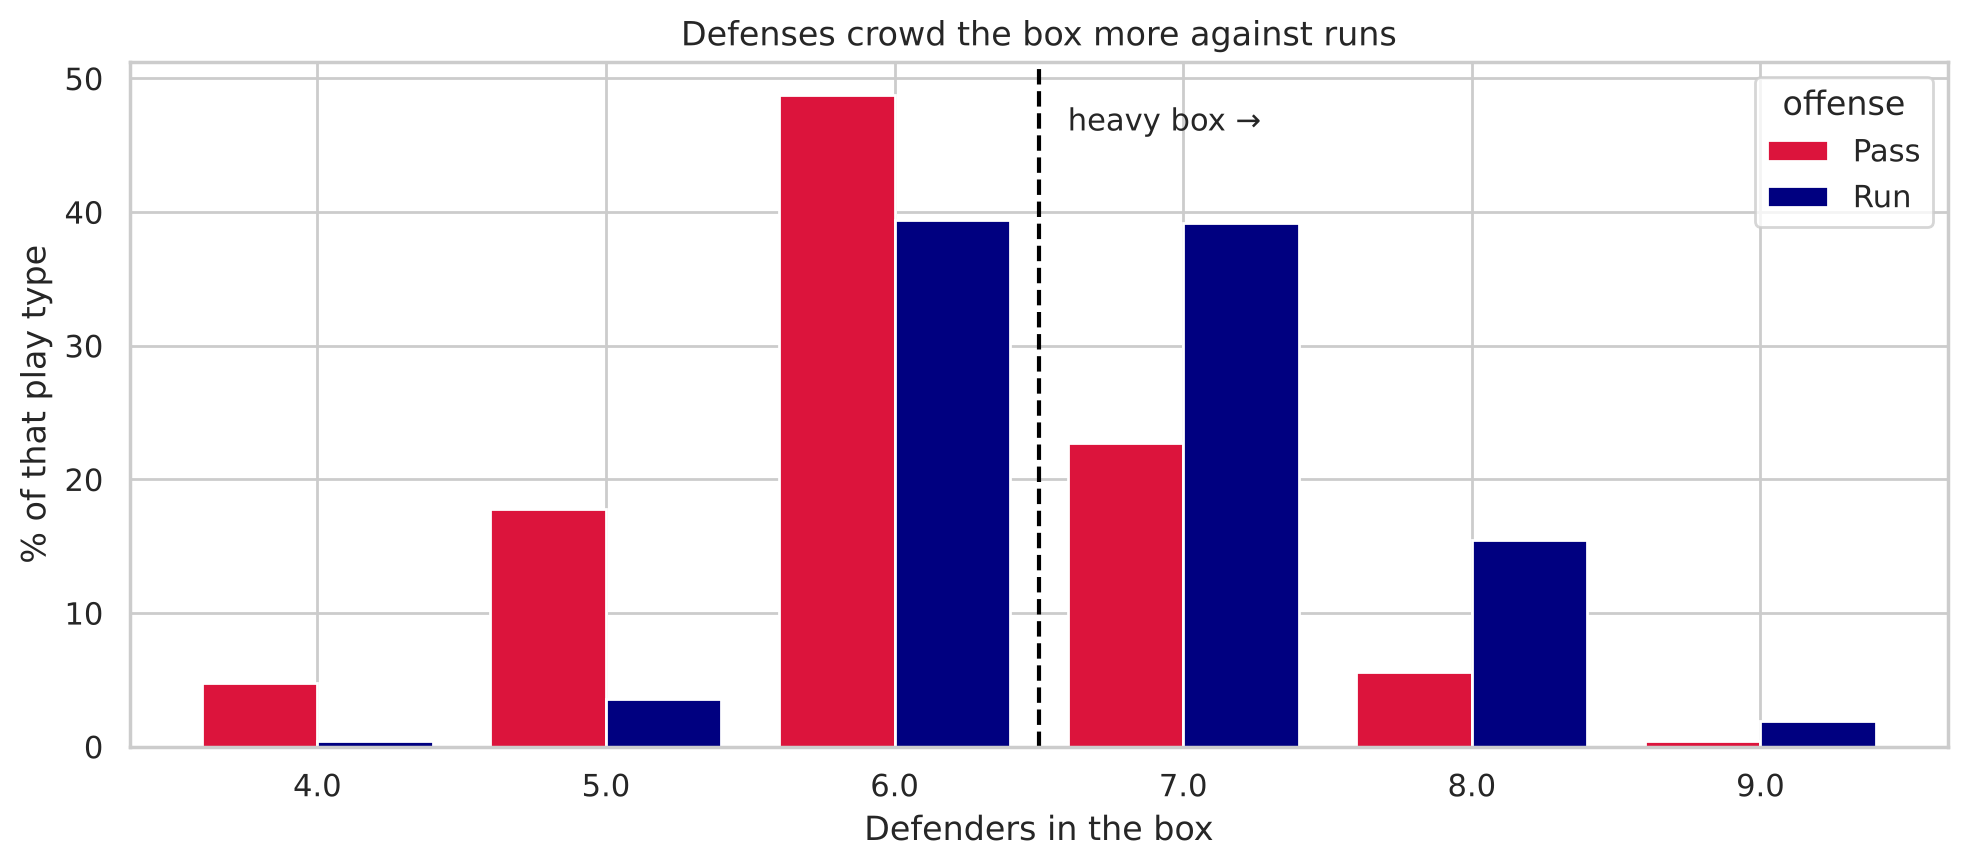

263,171 plays from 2016–2025


In [11]:
plays = pbp.merge(box, on=["game_id", "play_id"], how="inner")
plays = plays[((plays["pass"] == 1) | (plays["rush"] == 1)) & plays.defenders_in_box.notna() & plays.epa.notna()
              & (plays.qb_kneel == 0) & (plays.qb_spike == 0) & plays.wp.between(0.1, 0.9)].copy()
plays["offense"] = np.where(plays["pass"] == 1, "Pass", "Run")
plays["defense"] = np.where(plays.defenders_in_box >= 7, "heavy box", "light box")

fig, ax = plt.subplots(figsize=(10, 4.5))
counts = plays.groupby(["defenders_in_box", "offense"]).size().unstack().loc[4:9]
(counts / counts.sum() * 100).plot(kind="bar", ax=ax, color={"Pass": "crimson", "Run": "navy"}, width=.8)
ax.axvline(2.5, color="black", ls="--"); ax.text(2.6, ax.get_ylim()[1] * .9, "heavy box →", fontsize=11)
ax.set(xlabel="Defenders in the box", ylabel="% of that play type", title="Defenses crowd the box more against runs")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print(f"{len(plays):,} plays from 2016–2025")

### 3rd & short (1–2 yards to go)
The classic guessing game: a run can easily get 2 yards, but so can a quick pass, and the defense can't stop both.

In [12]:
def payoff_matrix(df):
    return df.pivot_table(index="offense", columns="defense", values="epa", aggfunc="mean").loc[["Run", "Pass"], ["heavy box", "light box"]]

third_short = plays[(plays.down == 3) & (plays.ydstogo <= 2)]
M_short = payoff_matrix(third_short)
show_game(M_short, f"3rd & 1–2: average EPA per play ({len(third_short):,} plays)", fmt="{:+.3f}")

,Defense: heavy box,Defense: light box
Offense: Run,+0.006 ◆,+0.062 ★
Offense: Pass,+0.052 ★,-0.021 ◆


> 🔍 **Check your understanding:** Read the stars and diamonds. Is there a pure Nash equilibrium on 3rd & short?

<details><summary><b>Click to reveal the answer</b></summary>

No. Against a heavy box the offense prefers to pass; against a light box it prefers to run. Against a pass the defense prefers a light box; against a run it prefers a heavy box. Nobody has a cell where both are happy, just like the toy game, so the equilibrium must be mixed.

</details>

                       Nash equilibrium   What NFL teams actually do
Offense pass rate            43.4%               43.3%
Defense heavy-box rate       64.8%               59.5%


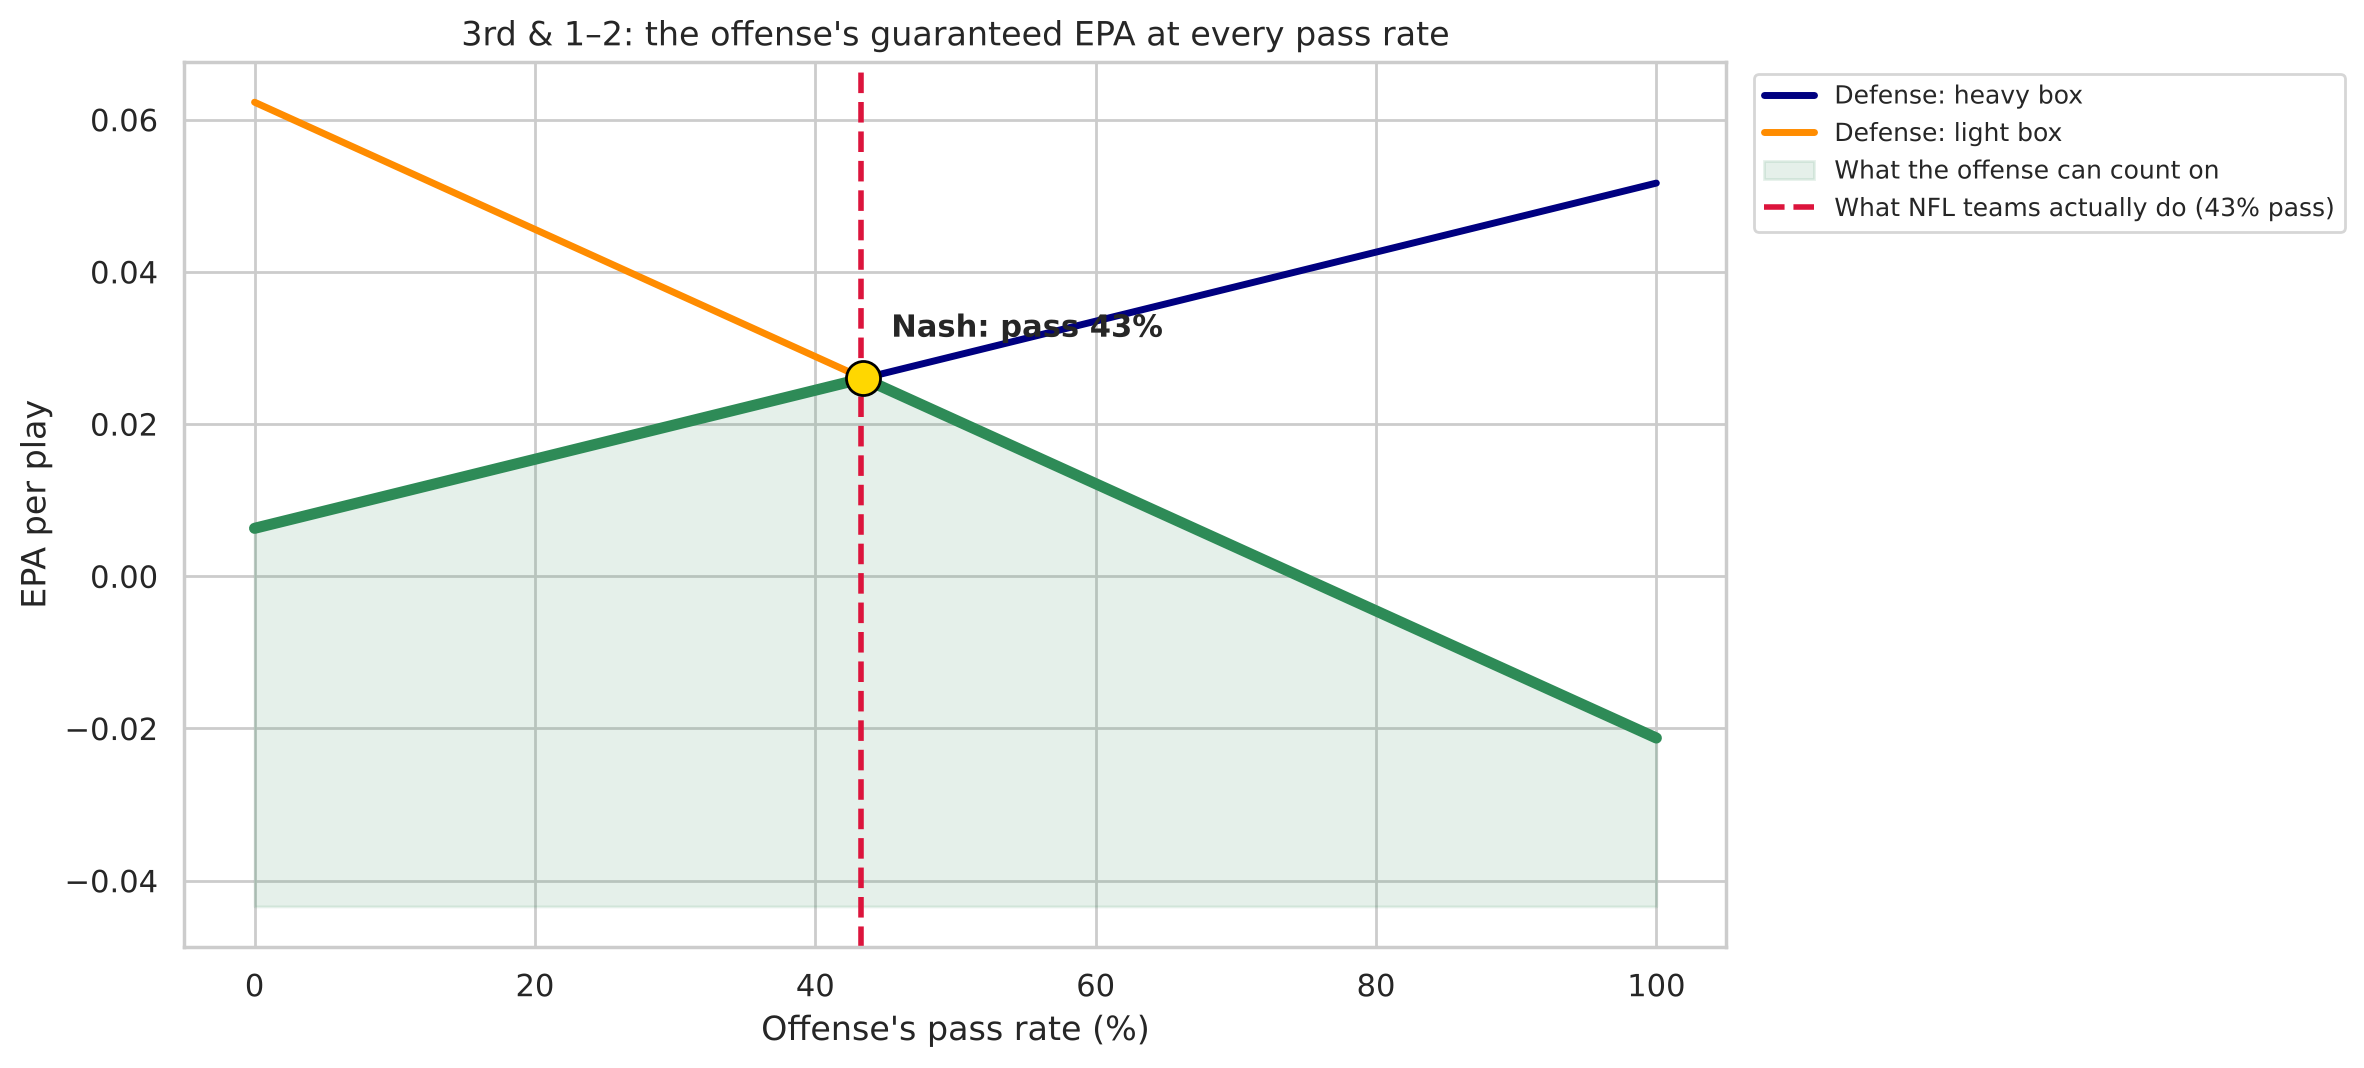

In [13]:
q_star, r_star, value = solve_2x2(M_short)
actual_pass = (third_short.offense == "Pass").mean()
actual_heavy = (third_short.defense == "heavy box").mean()

print("                       Nash equilibrium   What NFL teams actually do")
print(f"Offense pass rate            {q_star:5.1%}               {actual_pass:5.1%}")
print(f"Defense heavy-box rate       {r_star:5.1%}               {actual_heavy:5.1%}")
minimax_plot(M_short, "3rd & 1–2: the offense's guaranteed EPA at every pass rate", actual_q=actual_pass, units="EPA per play")

💡 **At face value, this is striking.** Nobody hands coaches a game-theory formula on 3rd down, yet the pass rate NFL offenses actually use is almost exactly the Nash mix, and defenses are in the same neighborhood. That's what you'd expect if decades of offenses and defenses adjusting to each other pushed them toward equilibrium.

But a good analyst asks: **how sure are we?**

### Bootstrapping
Our payoffs are averages from a sample of plays, so they're a bit noisy. **Bootstrapping** checks how much the answer could wobble: resample the plays with replacement many times, recompute the equilibrium each time, and look at the spread.

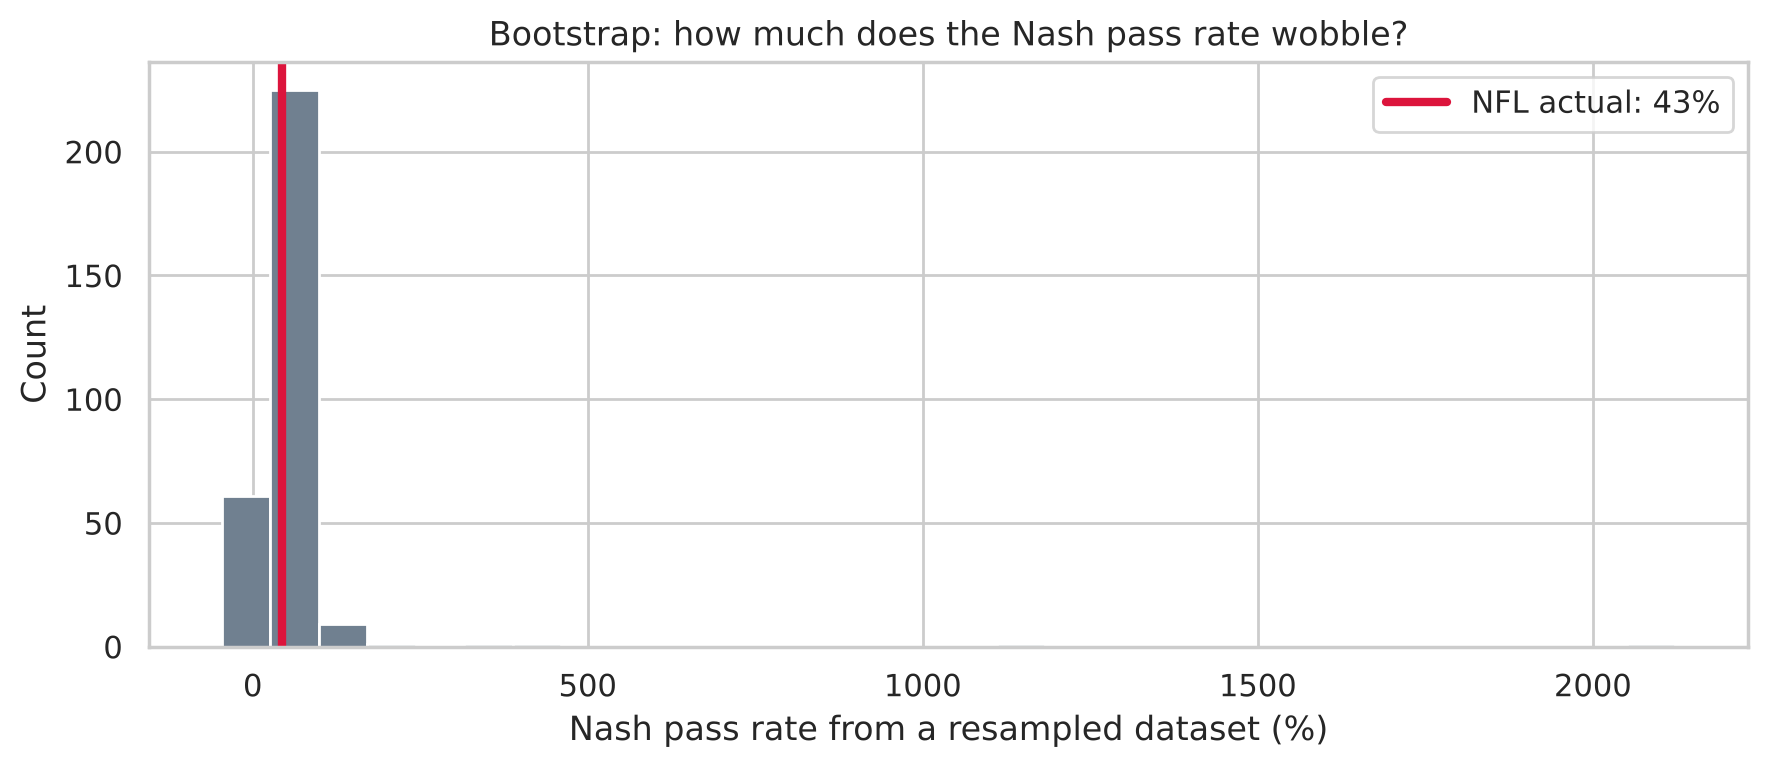

90% of bootstrap equilibria fall between 13% and 96%. The NFL's actual 43% is inside that range.


In [14]:
rng = np.random.default_rng(0)
boot = []
for _ in range(300):
    sample = third_short.sample(len(third_short), replace=True, random_state=rng.integers(1e9))
    boot.append(solve_2x2(payoff_matrix(sample))[0])
lo, hi = np.percentile(boot, [5, 95])

plt.figure(figsize=(9, 4))
plt.hist(np.array(boot) * 100, bins=30, color="slategray")
plt.axvline(actual_pass * 100, color="crimson", lw=3, label=f"NFL actual: {actual_pass:.0%}")
plt.xlabel("Nash pass rate from a resampled dataset (%)"); plt.ylabel("Count"); plt.legend()
plt.title("Bootstrap: how much does the Nash pass rate wobble?"); plt.tight_layout(); plt.show()
print(f"90% of bootstrap equilibria fall between {lo:.0%} and {hi:.0%}. The NFL's actual {actual_pass:.0%} is "
      f"{'inside' if lo <= actual_pass <= hi else 'outside'} that range.")

💡 **Honest conclusion:** the range is **very wide**. The four payoffs are close to each other, so small changes in them swing the equilibrium a lot. The data are **consistent** with teams playing the Nash mix on 3rd & short, but they can't prove teams are *exactly* there. The close match of the point estimates is suggestive, not proof.

> 🔍 **Check your understanding:** Why does the equilibrium wobble so much more than the payoffs themselves?

<details><summary><b>Click to reveal the answer</b></summary>

The formula divides by the *differences* between payoffs, and here those differences are tiny (a few hundredths of an expected point). Dividing by a small, noisy number makes the answer very sensitive. Whenever a result depends on small differences, check its uncertainty before trusting it.

</details>

### 1st & 10: a different story

In [15]:
first_10 = plays[(plays.down == 1) & (plays.ydstogo == 10)]
M_first = payoff_matrix(first_10)
show_game(M_first, f"1st & 10: average EPA per play ({len(first_10):,} plays)", fmt="{:+.3f}")
actual_pass_1st = (first_10.offense == "Pass").mean()
print(f"NFL teams pass on {actual_pass_1st:.0%} of 1st & 10 plays.")

,Defense: heavy box,Defense: light box
Offense: Run,-0.108 ◆,-0.069
Offense: Pass,+0.111 ★,+0.078 ★◆


NFL teams pass on 51% of 1st & 10 plays.


Here passing is better than running against **both** box types. When one strategy beats the other no matter what the opponent does, it's called a **dominant strategy**, and the equilibrium is simple: always play it. (Notice the gold border: a **pure** Nash equilibrium.)

So by this table, teams should pass on 1st & 10 far more than they do. This is one of the most famous findings in football analytics, and it's part of why passing has risen over the last decade.

> 🔍 **Check your understanding:** Before concluding coaches are wrong, list reasons the table might overstate the case for passing.

<details><summary><b>Click to reveal the answer</b></summary>

(1) **Payoffs aren't fixed.** If offenses passed every time, defenses would play pass defense on every snap, with better personnel and coverage than a light box captures, so passing would get worse. (2) **The box count is a rough stand-in** for what the defense is really expecting. (3) **Running has hidden benefits**: it sets up play-action passes, runs the clock, and avoids interceptions and injuries to the quarterback. (4) **Averages hide risk**: passes produce more turnovers, and some coaches care about avoiding disasters, not just the average. Good analysis states its assumptions and where they might fail.

</details>

### Every situation at once
The same calculation for several down-and-distance situations. When neither strategy dominates, we show the mixed Nash pass rate; when one dominates, the "equilibrium" is 0% or 100%.

,plays,type,Nash pass rate,actual pass rate
situation,,,,
1st & 10,"104,812",pass dominates,100%,51%
2nd & 1–3,"13,761",pass dominates,100%,36%
2nd & 4–7,"28,408",pass dominates,100%,58%
2nd & 8+,"45,352",pass dominates,100%,73%
3rd & 1–2,"10,828",mixed,43%,43%
3rd & 3–6,"17,968",run dominates,0%,92%
3rd & 7+,"25,574",pass dominates,100%,95%


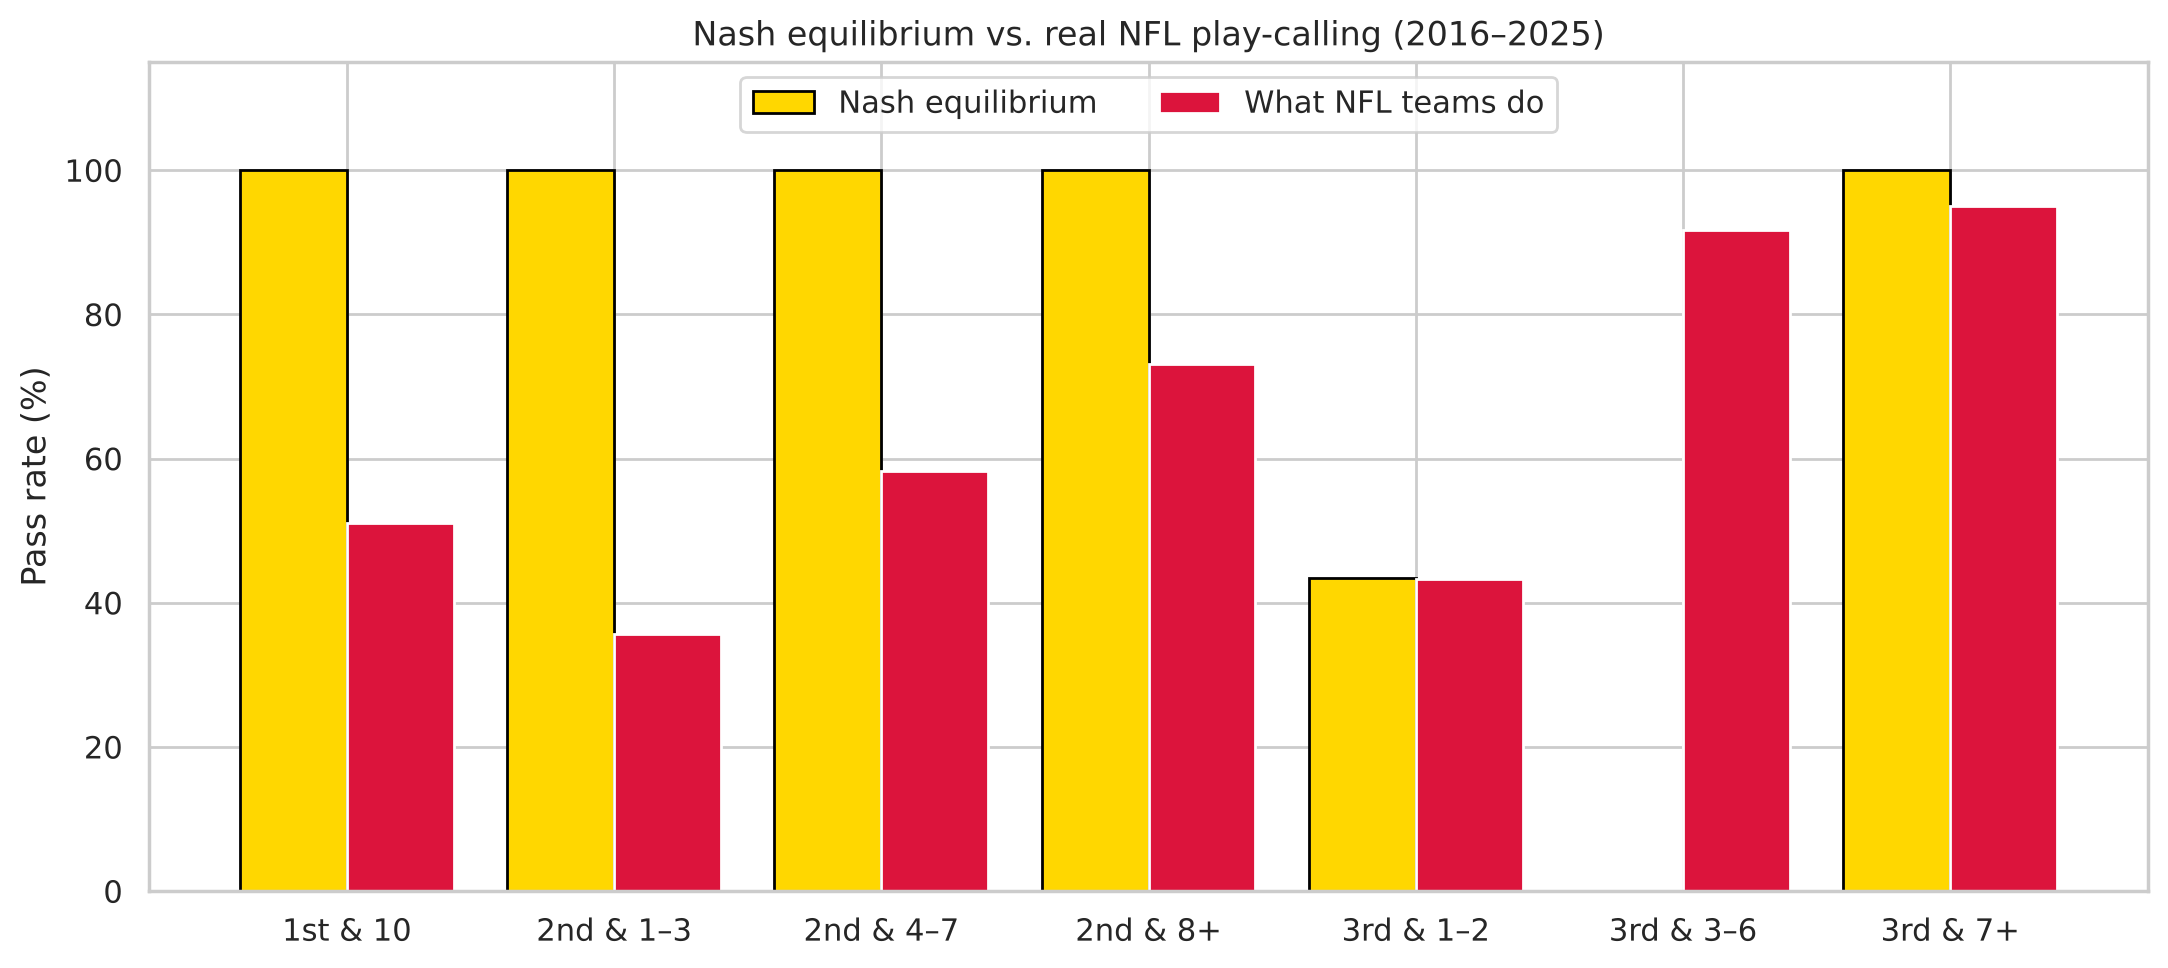

In [16]:
situations = {
    "1st & 10":    (plays.down == 1) & (plays.ydstogo == 10),
    "2nd & 1–3":   (plays.down == 2) & (plays.ydstogo <= 3),
    "2nd & 4–7":   (plays.down == 2) & plays.ydstogo.between(4, 7),
    "2nd & 8+":    (plays.down == 2) & (plays.ydstogo >= 8),
    "3rd & 1–2":   (plays.down == 3) & (plays.ydstogo <= 2),
    "3rd & 3–6":   (plays.down == 3) & plays.ydstogo.between(3, 6),
    "3rd & 7+":    (plays.down == 3) & (plays.ydstogo >= 7),
}
rows = []
for name, mask in situations.items():
    df = plays[mask]
    M = payoff_matrix(df)
    (a, b), (c, d) = M.values
    if c > a and d > b:   label, q = "pass dominates", 1.0
    elif a > c and b > d: label, q = "run dominates", 0.0
    else:                 label, q = "mixed", solve_2x2(M)[0]
    rows.append({"situation": name, "plays": len(df), "type": label,
                 "Nash pass rate": q, "actual pass rate": (df.offense == "Pass").mean()})
summary = pd.DataFrame(rows).set_index("situation")
display(summary.style.format({"plays": "{:,}", "Nash pass rate": "{:.0%}", "actual pass rate": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(11, 5))
xs = np.arange(len(summary))
ax.bar(xs - 0.2, summary["Nash pass rate"] * 100, 0.4, color="gold", edgecolor="black", label="Nash equilibrium")
ax.bar(xs + 0.2, summary["actual pass rate"] * 100, 0.4, color="crimson", label="What NFL teams do")
ax.set_xticks(xs); ax.set_xticklabels(summary.index)
ax.set(ylabel="Pass rate (%)", ylim=(0, 115), title="Nash equilibrium vs. real NFL play-calling (2016–2025)")
ax.legend(loc="upper center", ncol=2); plt.tight_layout(); plt.show()

> 🔍 **Check your understanding:** Two puzzles in the table: early downs say 'pass dominates' while teams run a lot, and 3rd & 3–6 says 'run dominates' while teams pass 92% of the time. What could explain them?

<details><summary><b>Click to reveal the answer</b></summary>

On early downs, see the caveats above: payoffs would change if offenses passed far more, and running has hidden benefits. On 3rd & 3–6, the answer is **selection bias**: teams almost never run there, so the few runs that happen are *surprises* that catch defenses in pass coverage. If teams ran often, defenses would expect it and those runs would stop working. Both puzzles teach the same lesson: the payoffs we measure come from how teams *currently* play, and they would change if behavior changed. Real play-calling matches the equilibrium where the game is a genuine guessing game (3rd & short) and where the answer is obvious (3rd & long).

</details>

### Team by team: who passes more on early downs, and does it pay off?
Each team's 2025 pass rate on 1st and 2nd down in competitive situations, against its offensive EPA per play.

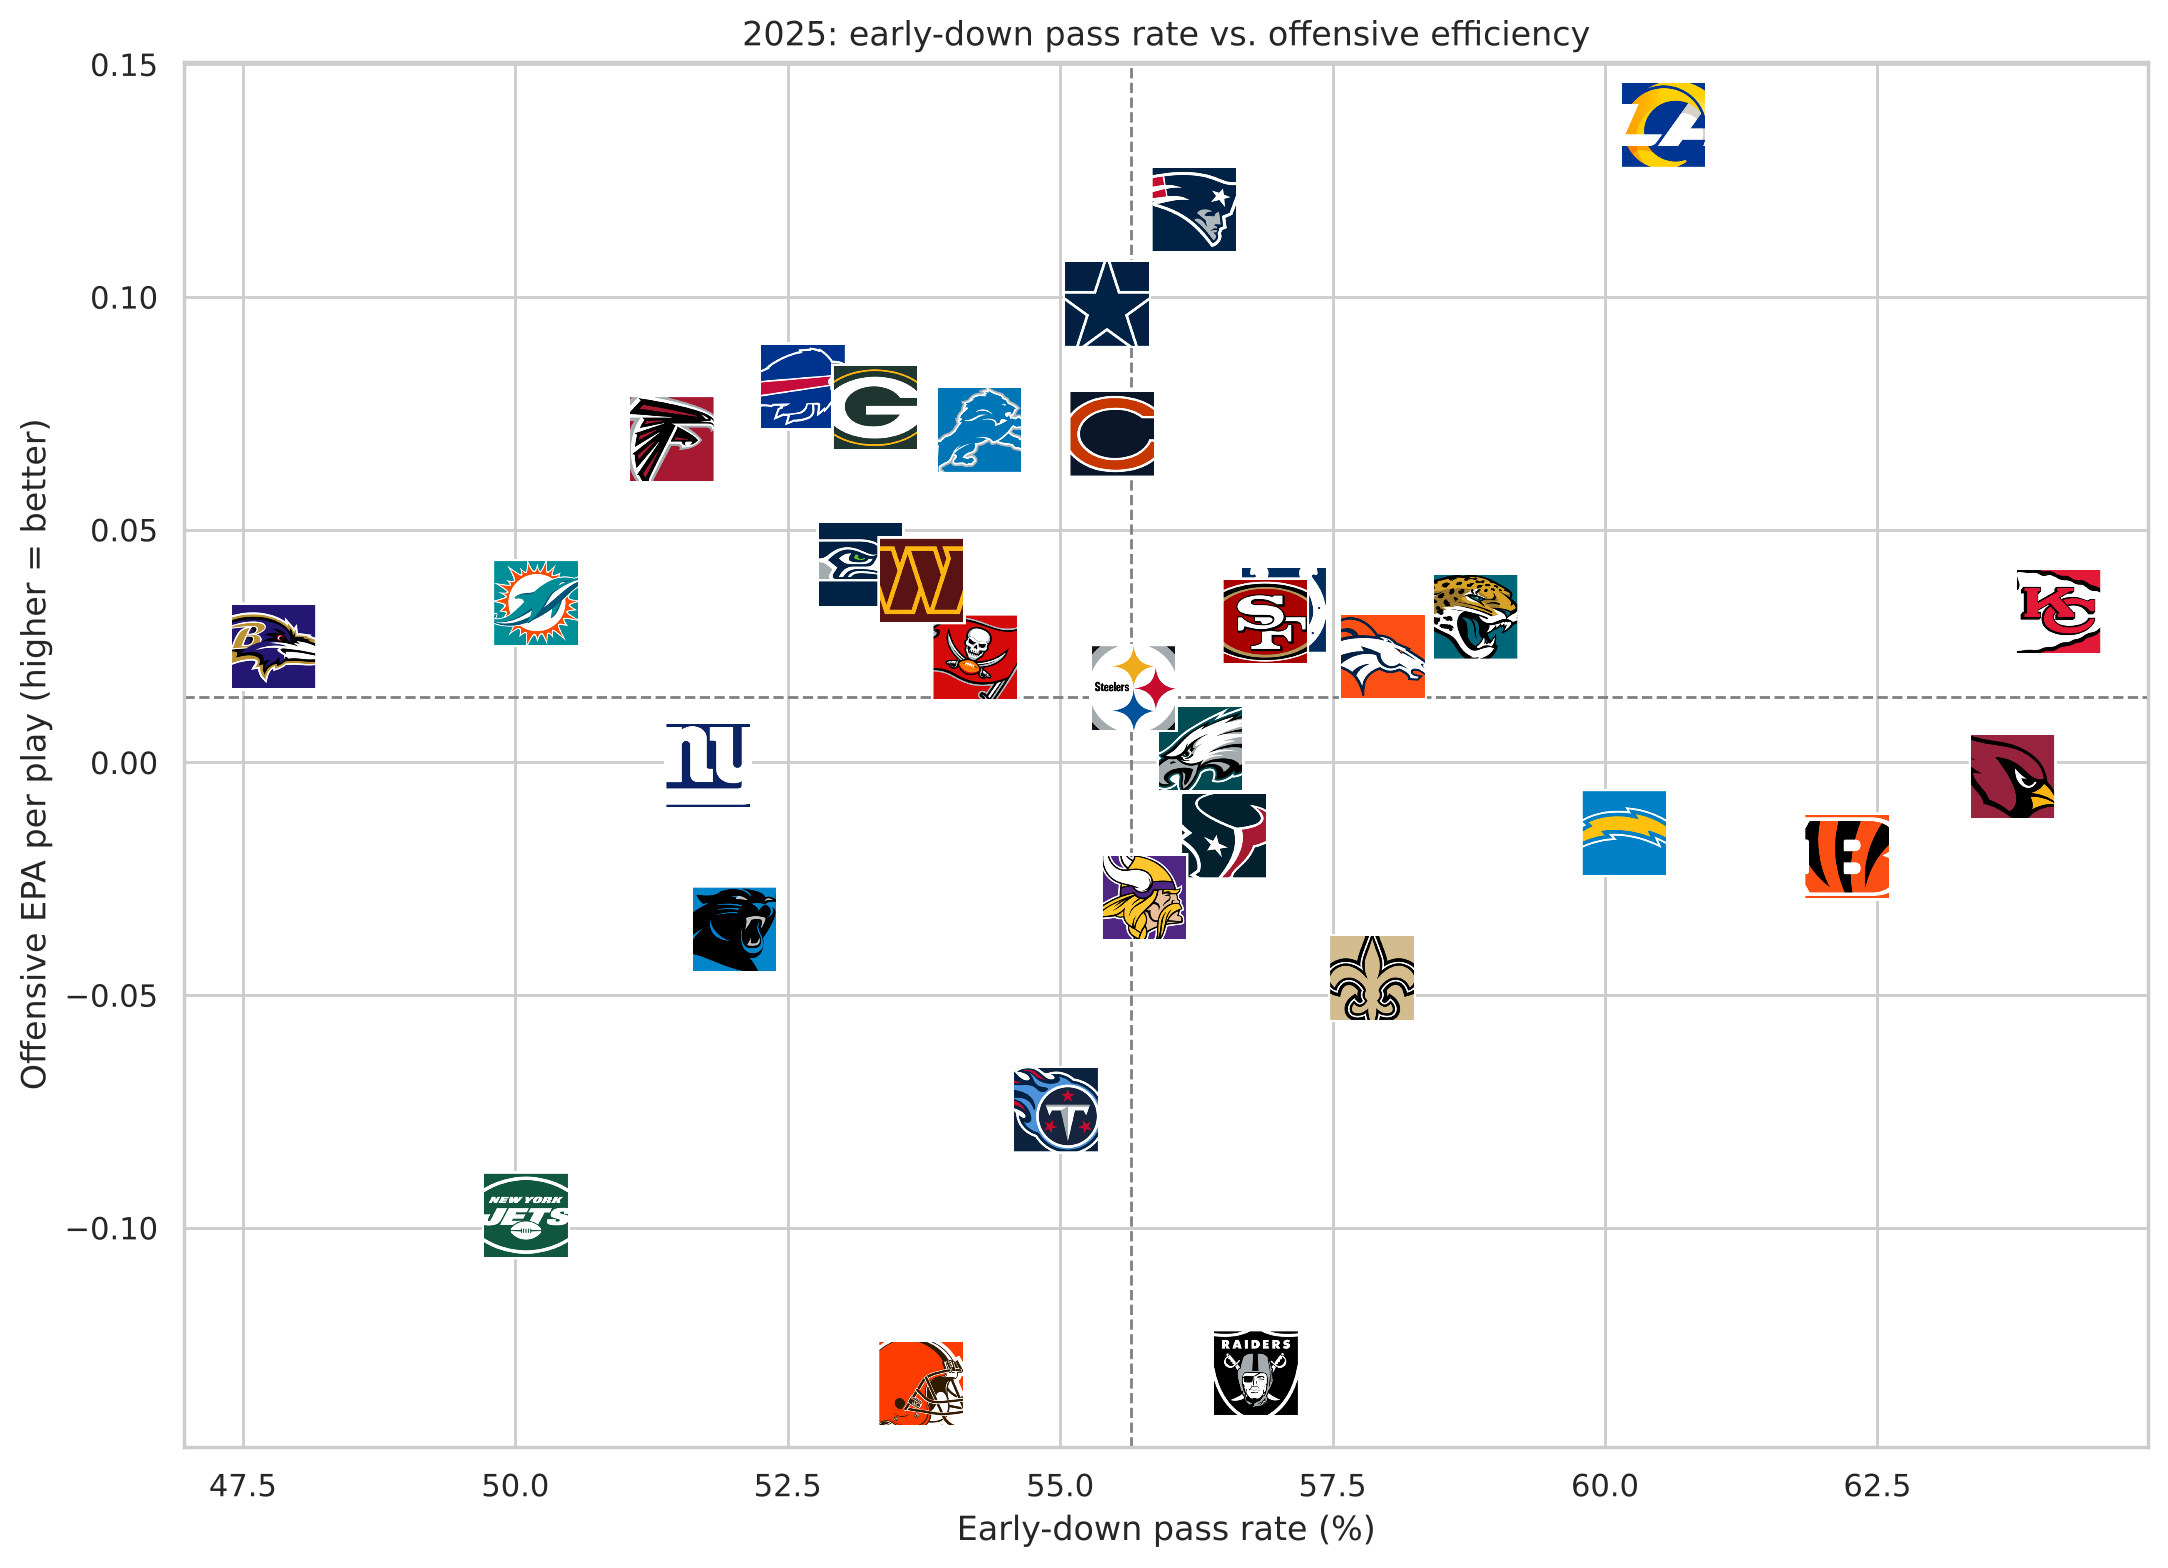

Correlation between early-down pass rate and EPA per play: 0.04


In [17]:
early = plays[(plays.season == 2025) & (plays.down <= 2)]
teams = early.groupby("posteam").agg(pass_rate=("offense", lambda s: (s == "Pass").mean()), epa=("epa", "mean"))

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(teams.pass_rate * 100, teams.epa, alpha=0)
for t, r in teams.iterrows():
    add_logo(ax, t, r.pass_rate * 100, r.epa, zoom=0.30)
ax.axvline(teams.pass_rate.mean() * 100, color="gray", ls="--", lw=1)
ax.axhline(teams.epa.mean(), color="gray", ls="--", lw=1)
ax.set(xlabel="Early-down pass rate (%)", ylabel="Offensive EPA per play (higher = better)",
       title="2025: early-down pass rate vs. offensive efficiency")
plt.tight_layout(); plt.show()
print(f"Correlation between early-down pass rate and EPA per play: {teams.pass_rate.corr(teams.epa):.2f}")

> 🔍 **Check your understanding:** The correlation is close to zero. Does that mean passing more doesn't help an offense?

<details><summary><b>Click to reveal the answer</b></summary>

Not necessarily. Pass rate is a *choice* that teams make based on their own strengths: a team with a weak quarterback may run more because passing doesn't work for them, while a team with a star QB passes more. Each team may be choosing sensibly for its roster, which can wipe out any league-wide pattern. A team-level correlation can't tell us what would happen if one team changed its pass rate.

</details>

## Part 5 · Limitations and exercises

### What our models leave out
* **The decision tree** assumes you'll score the second touchdown, the opponent won't score, and overtime is 50/50. Real games have time, field position and team strength.
* **The payoff matrices** treat the defense's choice as just "heavy or light box." Real defenses also choose coverages, blitzes and personnel.
* **Payoffs depend on behavior.** If one side changed its mix a lot, the other side's counters would change too, so the averages we measured wouldn't stay the same.
* **Averages hide risk.** EPA is an average; coaches may reasonably care about avoiding turnovers or big losses, not only the average.

### ✏️ Exercises

**Expected value**
1. **Down 8 with no time for anything else.** You just scored to make it down 2. Write the decision tree for kicking vs. going for 2, and compute each chance of winning.
2. **Your own team.** Change `p` to a 2-point success rate of 40% and then 60% and rerun Part 1. How does the advantage of going for 2 first change?

**Game theory**

3. **Solve by hand.** For this game (yards gained), find the offense's Nash pass rate and the value of the game, then check with `solve_2x2`:

| | expects run | expects pass |
|---|---|---|
| **Run** | 3 | 7 |
| **Pass** | 8 | 2 |

4. **Change the definition.** Redefine a heavy box as **8 or more** defenders. Does the 3rd & short equilibrium still match what teams do?
5. **Use success instead of EPA.** Replace `values="epa"` with `values="success"` (whether the play gained enough to be considered successful) in `payoff_matrix`. Do the conclusions change?
6. **2-point tries as a game.** Build a run/pass payoff matrix for 2-point attempts only (payoff = success). Hint: you'll need the `two_point_conv_result` column and the box count. Is the sample big enough to trust?
7. **Red zone.** Repeat the 3rd & short analysis for plays inside the opponent's 10-yard line (`yardline_100 <= 10`).